# DSA4262 Team Project — Exploratory Data Analysis
**Prediction of m6A RNA modifications from direct RNA-Seq data**

This notebook explores the three datasets and identifies the pitfalls we must handle when building the model.

| Dataset | What it is | Labels |
|---|---|---|
| `data0` | Training data, HCT116 colon cancer cell line | 0/1 per site (m6ACE-Seq) |
| `data1` | A second real dataset (origin to confirm with instructors) | 0/1 per site |
| `data2` | 7 synthetic transcripts with a known modification fraction | 0, 0.25, 0.5, 0.7, 0.75, 0.95, 1 |

**How to run:** put (or link) the `data0`, `data1` and `data2` folders in the repo's `data/` folder (see `data/README.md`), then run all cells from `notebooks/`. The first run parses the json files (~7–10 minutes) and caches them in `notebooks/cache/`; later runs take seconds.

**Sections**
1. Setup and parsing
2. Class balance
3. Reads per site
4. Genes, transcripts and clustering of positives
5. The 5-mer (sequence) effect
6. Which signal features carry information (Simpson's paradox)
7. Outliers in read-level features
8. Overlap and label disagreement between data0 and data1
9. Batch effects between datasets
10. data2: signal vs modification fraction
11. Baselines and the cost of data leakage
12. Summary figure and list of pitfalls

## 1. Setup and parsing

In [1]:
from pathlib import Path
import gzip, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split

# Paths: the notebook lives in notebooks/, the data in ../data (see data/README.md)
DATA = Path('../data')
CACHE = Path('cache'); CACHE.mkdir(exist_ok=True)

# The 9 features recorded for every read:
# dwell time (dt), signal standard deviation (sd) and mean current (mean)
# at the -1 flanking position (m1), the candidate site (0) and the +1 position (p1)
FEATS = ['dt_m1','sd_m1','mean_m1','dt_0','sd_0','mean_0','dt_p1','sd_p1','mean_p1']
pd.set_option('display.width', 140)

### Parse json → one row per site
Each line of `dataset*.json.gz` is one candidate site with a variable number of reads (each read = 9 numbers).
To explore the data we summarise every site by the **mean, standard deviation and median** of each feature across its reads, and we also keep a random sample of up to 20 raw reads per site for read-level checks.

In [2]:
def parse_dataset(json_path, seed=0):
    """Return (site-level summary table, sample of raw reads) for one dataset."""
    rng = np.random.default_rng(seed)
    rows, samples = [], []
    with gzip.open(json_path, 'rt') as fh:
        for line in fh:
            for tx, positions in json.loads(line).items():
                for pos, kmers in positions.items():
                    for kmer, reads in kmers.items():
                        a = np.asarray(reads, dtype=np.float32)
                        r = {'transcript_id': tx, 'transcript_position': int(pos),
                             'kmer': kmer, 'n_reads': len(a)}
                        for i, f in enumerate(FEATS):
                            col = a[:, i]
                            r[f + '_mean'] = col.mean(); r[f + '_std'] = col.std(); r[f + '_med'] = np.median(col)
                        rows.append(r)
                        idx = rng.choice(len(a), min(20, len(a)), replace=False)
                        s = pd.DataFrame(a[idx], columns=FEATS)
                        s['transcript_id'] = tx; s['transcript_position'] = int(pos); s['kmer'] = kmer
                        samples.append(s)
    return pd.DataFrame(rows), pd.concat(samples, ignore_index=True)

def load(name, json_rel):
    """Parse once, then reuse the cached parquet files."""
    f_sites, f_reads = CACHE / f'{name}_sites.parquet', CACHE / f'{name}_reads_sample.parquet'
    if not f_sites.exists():
        print(f'parsing {json_rel} ...')
        sites, reads = parse_dataset(DATA / json_rel)
        sites.to_parquet(f_sites); reads.to_parquet(f_reads)
    return pd.read_parquet(f_sites), pd.read_parquet(f_reads)

site0, reads0 = load('d0', 'data0/dataset0.json.gz')
site1, _      = load('d1', 'data1/dataset1.json.gz')
site2, _      = load('d2', 'data2/dataset2.json.gz')

info0 = pd.read_csv(DATA / 'data0/data.info.labelled')
info1 = pd.read_csv(DATA / 'data1/data.info')
info2 = pd.read_csv(DATA / 'data2/data.info')

KEY = ['transcript_id', 'transcript_position']
s0 = site0.merge(info0, on=KEY)
s1 = site1.merge(info1[KEY + ['label']], on=KEY)
s2 = site2.merge(info2[KEY + ['label']], on=KEY)
for s in (s0, s1, s2):
    s['k5'] = s.kmer.str[1:6]          # central 5-mer = the DRACH motif

print('sites  d0:', len(s0), ' d1:', len(s1), ' d2:', len(s2))
print('every json site has a label in d0:', len(s0) == len(site0) == len(info0))
print('duplicate site keys in d0:', s0.duplicated(KEY).sum())
s0.head(3)

sites  d0: 121838  d1: 90810  d2: 1323
every json site has a label in d0: True
duplicate site keys in d0: 0


,transcript_id,transcript_position,kmer,n_reads,dt_m1_mean,dt_m1_std,dt_m1_med,sd_m1_mean,sd_m1_std,sd_m1_med,...,dt_p1_med,sd_p1_mean,sd_p1_std,sd_p1_med,mean_p1_mean,mean_p1_std,mean_p1_med,gene_id,label,k5
0,ENST00000000233,244,AAGACCA,185,0.008264,0.005384,0.00697,4.223784,1.843025,3.73,...,0.00598,4.386989,2.906225,3.44,80.570267,2.522168,80.500000,ENSG00000004059,0,AGACC
1,ENST00000000233,261,CAAACTG,172,0.006609,0.003588,0.00564,3.216424,1.689167,2.88,...,0.00679,3.016599,1.466295,2.66,94.290703,2.492530,94.099998,ENSG00000004059,0,AAACT
2,ENST00000000233,316,GAAACAG,185,0.007570,0.004444,0.00631,2.940541,1.311103,2.65,...,0.00631,2.087146,0.800496,1.91,89.364326,1.484341,89.199997,ENSG00000004059,0,AAACA


**What this means:** all 121,838 sites in `data0` match exactly one label and there are no duplicate sites, so the join on `transcript_id` + `transcript_position` is clean. Note that `data0` has `gene_id` in its info file but `data1`/`data2` do not.

## 2. Class balance

In [3]:
print('d0 label counts:', s0.label.value_counts().to_dict(), '| positive rate = %.3f' % s0.label.mean())
print('d1 label counts:', s1.label.value_counts().to_dict(), '| positive rate = %.3f' % s1.label.mean())
print('d2 label values :', s2.label.value_counts().sort_index().to_dict())

d0 label counts: {0: 116363, 1: 5475} | positive rate = 0.045
d1 label counts: {0: 84217, 1: 6593} | positive rate = 0.073
d2 label values : {0.0: 189, 0.25: 189, 0.5: 189, 0.7: 189, 0.75: 189, 0.95: 189, 1.0: 189}


**What this means — Pitfall 1: strong class imbalance.**
- Only **4.5%** of `data0` sites are modified. A model that always predicts "unmodified" would be 95.5% accurate, so **accuracy is useless** here. We use **ROC AUC and PR AUC**; for PR AUC a random classifier scores about the positive rate (≈0.045), which is the reference line to beat.
- The positive rate differs between datasets (7.3% in `data1`), so the leaderboard test set may have a different prevalence — PR AUC values are not directly comparable across datasets.
- `data2` labels are **fractions**, not 0/1: they tell us what share of molecules is modified (see Section 10).

## 3. Reads per site

In [4]:
pct = [.05, .25, .5, .75, .95, .99]
print(pd.DataFrame({n: s.n_reads.describe(percentiles=pct) for n, s in [('d0', s0), ('d1', s1), ('d2', s2)]}).round(0))

# Does read depth relate to the label? Positive rate per read-depth decile:
print(s0.groupby(pd.qcut(s0.n_reads, 10), observed=True).label.agg(['mean', 'size']).round(3))

             d0       d1      d2
count  121838.0  90810.0  1323.0
mean       91.0     87.0   886.0
std       137.0    146.0   565.0
min        20.0     20.0    26.0
5%         22.0     21.0   112.0
25%        32.0     27.0   440.0
50%        47.0     40.0   814.0
75%        84.0     77.0  1270.0
95%       304.0    312.0  1868.0
99%       869.0    893.0  2395.0
max       991.0    994.0  3438.0
                 mean   size
n_reads                     
(19.999, 25.0]  0.041  14640
(25.0, 29.0]    0.048  10464
(29.0, 34.0]    0.044  12248
(34.0, 40.0]    0.044  12546
(40.0, 47.0]    0.044  11386
(47.0, 57.0]    0.047  12281
(57.0, 73.0]    0.045  12261
(73.0, 100.0]   0.038  11799
(100.0, 175.0]  0.053  12069
(175.0, 991.0]  0.046  12144


**What this means — Pitfall 2: variable and shifting read depth.**
- In `data0` each site has between **20 and 991 reads (median 47)**; the minimum of 20 shows the data was pre-filtered. We need a fixed-length representation for a variable number of reads (summaries such as mean/median/quantiles, or a read-level model with pooling like m6Anet).
- The positive rate is flat (~4–5%) across all depth deciles, so **read depth itself is not predictive** — good, but features that scale with the read count (sums, raw counts) must be avoided.
- `data2` has a median of **814 reads**, ~17× deeper. A test set can look very different in depth, and averages from sites with few reads are noisier.

## 4. Genes, transcripts and clustering of positives

In [5]:
g = info0.groupby('gene_id').agg(n_sites=('label', 'size'), n_pos=('label', 'sum'),
                                 n_tx=('transcript_id', 'nunique'))
print('genes:', len(g), '| transcripts:', info0.transcript_id.nunique())
print('sites per gene:', g.n_sites.describe().round(1).to_dict())
print('genes with >1 transcript:', (g.n_tx > 1).sum())
print('genes with at least one positive: %.1f%%' % (100 * (g.n_pos > 0).mean()))
top10 = g.n_pos.sort_values(ascending=False).head(int(len(g) * .1)).sum() / g.n_pos.sum()
print('share of all positives found in the top 10%% of genes: %.1f%%' % (100 * top10))

# Are positives clustered along a transcript?
s0 = s0.sort_values(KEY).reset_index(drop=True)
s0['gap'] = s0.groupby('transcript_id').transcript_position.diff()
s0['prev_label'] = s0.groupby('transcript_id').label.shift()
near = s0[s0.gap <= 20]
print('P(positive | previous site within 20 nt is positive) = %.3f' % near[near.prev_label == 1].label.mean())
print('P(positive | previous site within 20 nt is negative) = %.3f' % near[near.prev_label == 0].label.mean())

genes: 3852 | transcripts: 5333
sites per gene: {'count': 3852.0, 'mean': 31.6, 'std': 27.7, 'min': 1.0, '25%': 14.0, '50%': 25.0, '75%': 41.0, 'max': 274.0}
genes with >1 transcript: 954
genes with at least one positive: 39.1%
share of all positives found in the top 10% of genes: 60.5%
P(positive | previous site within 20 nt is positive) = 0.299
P(positive | previous site within 20 nt is negative) = 0.030


**What this means — Pitfall 3: positives cluster within genes → data leakage risk.**
- 3,852 genes and 5,333 transcripts; 954 genes have several transcripts, which can contain the *same* genomic site with near-identical reads.
- Only 39% of genes have any positive, and the top 10% of genes hold **~61% of all positives**.
- A site next to a positive site is **~10× more likely** to be positive itself (0.30 vs 0.03).

So if sites of one gene end up in both the training and the test set, the model can partly "recognise the gene" instead of learning the m6A signal, and the test score is inflated. **The train/test split (and cross-validation folds) must be grouped by `gene_id`** (`GroupKFold` / `GroupShuffleSplit`). Section 11 measures how much a random split inflates the score.

## 5. The 5-mer (sequence) effect

In [6]:
k = s0.groupby('k5').label.agg(pos_rate='mean', n_sites='size').sort_values('pos_rate', ascending=False)
print('distinct 5-mers:', s0.k5.nunique(), '| distinct 7-mers:', s0.kmer.nunique())
k.round(3)

distinct 5-mers: 18 | distinct 7-mers: 288


,pos_rate,n_sites
k5,,
GGACT,0.226,6376
GAACT,0.113,6957
GGACA,0.089,7727
AGACT,0.082,6405
GGACC,0.075,7353
TGACT,0.063,6789
AAACT,0.030,8627
GAACA,0.024,7934
GAACC,0.022,5719


**What this means — Pitfall 4: the sequence alone is very predictive.**
- All sites fall into the 18 DRACH 5-mers, but their m6A rate varies from **22.6% (GGACT)** to **0% (TAACA)** — GGACT is the canonical m6A motif.
- A model could score well by learning only the sequence. That is a valid prior, but it is not *detecting* modification from the signal. We should report a **sequence-only baseline** (Section 11) and show our model adds information beyond it.
- The 5-mer must be encoded as a feature (e.g. one-hot of the 7-mer or the three 5-mers) because the "normal" current level depends on it (next section).

## 6. Which signal features carry information? (Simpson's paradox)

In [7]:
def cohen_d(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

rows = []
for f in [c for c in s0.columns if c.endswith('_mean') and c[:-5] in FEATS]:
    raw = cohen_d(s0.loc[s0.label == 1, f], s0.loc[s0.label == 0, f])
    # z-score the feature within each 5-mer, then compare positives vs negatives
    z = s0.groupby('k5')[f].transform(lambda x: (x - x.mean()) / x.std())
    within = cohen_d(z[s0.label == 1], z[s0.label == 0])
    rows.append((f, raw, within))
eff = pd.DataFrame(rows, columns=['feature', 'effect_raw', 'effect_within_5mer'])
eff.sort_values('effect_within_5mer', key=abs, ascending=False).round(3)

,feature,effect_raw,effect_within_5mer
5,mean_0_mean,0.364,-0.691
4,sd_0_mean,-0.045,-0.524
8,mean_p1_mean,0.133,-0.407
2,mean_m1_mean,0.571,-0.247
3,dt_0_mean,0.095,-0.198
1,sd_m1_mean,0.170,-0.173
7,sd_p1_mean,0.036,-0.136
0,dt_m1_mean,0.172,-0.045
6,dt_p1_mean,0.183,-0.031


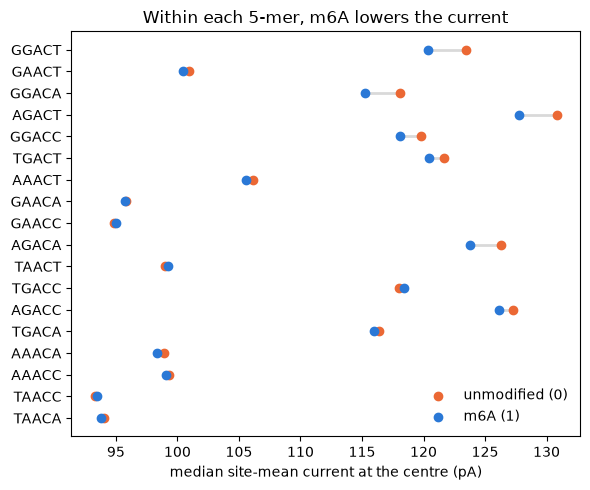

In [8]:
# Median centre current of positive vs negative sites inside each 5-mer
order = k.sort_values('pos_rate').index
m = s0.groupby(['k5', 'label']).mean_0_mean.median().unstack().loc[order]
fig, ax = plt.subplots(figsize=(6, 5))
for i, (neg, pos) in enumerate(zip(m[0], m[1])):
    ax.plot([neg, pos], [i, i], color='#d9d9d9', lw=2, zorder=1)
ax.scatter(m[0], range(len(m)), color='#eb6834', label='unmodified (0)', zorder=2)
ax.scatter(m[1], range(len(m)), color='#2a78d6', label='m6A (1)', zorder=2)
ax.set_yticks(range(len(m)), m.index); ax.set_xlabel('median site-mean current at the centre (pA)')
ax.set_title('Within each 5-mer, m6A lowers the current'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**What this means — Pitfall 5: raw features are confounded by the sequence.**
- Looking at all sites together, modified sites seem to have a **higher** centre current (effect +0.36). Within each 5-mer the opposite is true: m6A **lowers** the current (effect −0.69). This reversal is **Simpson's paradox**: the 5-mers with the most m6A (GG-ACT etc.) simply have a high baseline current.
- Therefore the current only makes sense *relative to its 5-mer*: either normalise features per 5-mer (subtract the 5-mer's typical value) or always give the model the k-mer alongside the signal.
- The strongest within-5-mer signals are the **centre mean current**, the **centre SD** and the **+1 position mean current**; dwell times carry little information on average. These should be prioritised in feature engineering.

## 7. Outliers in read-level features

In [9]:
q = reads0[['dt_0', 'sd_0', 'mean_0']].quantile([.01, .5, .99, .999]).T
q['max'] = reads0[['dt_0', 'sd_0', 'mean_0']].max()
q.round(4)

,0.01,0.5,0.99,0.999,max
dt_0,0.0023,0.0066,0.0272,0.0415,0.121
sd_0,1.3300,4.2000,13.9000,17.1000,181.000
mean_0,89.7000,112.0000,134.0000,137.0000,149.000


**What this means — Pitfall 6: heavy-tailed features.**
The centre SD has a 99.9th percentile of ~17 but a maximum of **181**, and dwell time is right-skewed. A few bad reads (segmentation errors) can drag a site's mean and SD. Use robust summaries (**median, quantiles**), clip or log-transform skewed features, and prefer tree models that are insensitive to monotone transformations.

## 8. Overlap and label disagreement between data0 and data1

In [10]:
ov = s0.merge(s1, on=KEY, suffixes=('_d0', '_d1'))
print('transcripts in d1 also in d0:', len(set(s1.transcript_id) & set(s0.transcript_id)), 'of', s1.transcript_id.nunique())
print('sites in d1 also in d0     :', len(ov), 'of', len(s1))
pd.crosstab(ov.label_d0, ov.label_d1, rownames=['label in d0'], colnames=['label in d1'])

transcripts in d1 also in d0: 3432 of 4451
sites in d1 also in d0     : 67320 of 90810


label in d1,0,1
label in d0,,
0,61312,2717
1,1155,2136


**What this means — Pitfall 7: noisy, sample-specific labels.**
- `data1` shares 67,320 of its 90,810 sites with `data0` (same transcripts, same positions).
- On those shared sites the labels **disagree 3,872 times** (2,717 go 0→1, 1,155 go 1→0). Either m6A really differs between the two samples, or the m6ACE-Seq labels are imperfect. In both cases some "negatives" in training are actually modified, which caps the achievable PR AUC and argues against over-tuning to the training labels.
- If we use `data1` as an independent validation set we must **remove the overlapping transcripts/genes**, otherwise the test leaks.

## 9. Batch effects between datasets

In [11]:
neg = lambda s: s[s.label == 0]
shift = pd.DataFrame({
    'd0': neg(s0).groupby('k5').mean_0_mean.median(),
    'd1': neg(s1).groupby('k5').mean_0_mean.median(),
    'd2': neg(s2).groupby('k5').mean_0_mean.median()})
shift['d1 - d0'] = shift.d1 - shift.d0
shift['d2 - d0'] = shift.d2 - shift.d0
print('median centre SD of unmodified sites  d0/d1/d2:',
      [round(float(neg(s).sd_0_mean.median()), 3) for s in (s0, s1, s2)])
shift.round(2)

median centre SD of unmodified sites  d0/d1/d2: [4.626, 4.858, 4.299]


,d0,d1,d2,d1 - d0,d2 - d0
k5,,,,,
AAACA,98.900002,98.889999,98.940002,-0.01,0.04
AAACC,99.349998,99.370003,97.599998,0.02,-1.75
AAACT,106.160004,105.889999,106.760002,-0.28,0.60
AGACA,126.309998,126.239998,125.889999,-0.08,-0.42
AGACC,127.279999,127.050003,126.510002,-0.23,-0.77
AGACT,130.839996,130.639999,130.820007,-0.20,-0.02
GAACA,95.849998,95.650002,95.330002,-0.20,-0.52
GAACC,94.839996,94.599998,94.169998,-0.24,-0.66
GAACT,100.930000,100.699997,101.550003,-0.23,0.62


**What this means — Pitfall 8: distribution shift (batch effects, Week 6 lecture).**
- For the *same unmodified 5-mers*, `data1` reads **0.2–0.4 pA lower** in current and has a larger SD (4.86 vs 4.63); `data2` deviates by up to ±1.7 pA. These are differences in run/chemistry/sample, not biology.
- The m6A signal itself is only ~1–3 pA (Section 10), so a batch shift of this size is not negligible. A model tuned only on `data0` may transfer poorly — the leaderboard data "may be a different cell type". Consider **per-dataset normalisation** (e.g. standardise each feature within 5-mer within dataset) and always check **cross-dataset performance**.

## 10. data2: signal vs modification fraction

               n_sites  label  first_pos  last_pos
transcript_id                                     
tx_id_0            189   1.00          0      1880
tx_id_1            189   0.95          0      1880
tx_id_2            189   0.75          0      1880
tx_id_3            189   0.70          0      1880
tx_id_4            189   0.50          0      1880
tx_id_5            189   0.25          0      1880
tx_id_6            189   0.00          0      1880
       mean_0_rel  sd_0_mean  dt_0_mean
label                                  
0.00        1.948      5.052      0.008
0.25        1.136      4.970      0.008
0.50        0.298      4.897      0.008
0.70       -0.351      4.860      0.008
0.75       -0.529      4.831      0.008
0.95       -1.170      4.774      0.008
1.00       -1.333      4.773      0.008


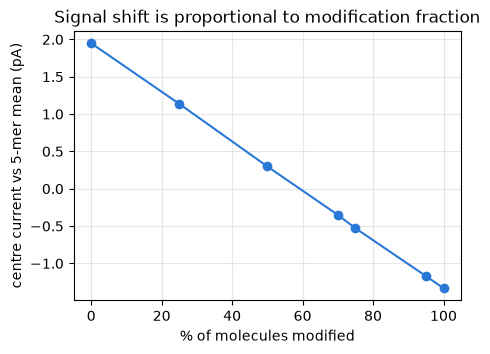

In [12]:
print(s2.groupby('transcript_id').agg(n_sites=('label', 'size'), label=('label', 'first'),
                                      first_pos=('transcript_position', 'min'), last_pos=('transcript_position', 'max')))
# centre current relative to the 5-mer average, per modification fraction
s2['mean_0_rel'] = s2.mean_0_mean - s2.groupby('k5').mean_0_mean.transform('mean')
d2 = s2.groupby('label')[['mean_0_rel', 'sd_0_mean', 'dt_0_mean']].mean()
print(d2.round(3))
plt.figure(figsize=(5, 3.5))
plt.plot(d2.index * 100, d2.mean_0_rel, marker='o', color='#2a78d6')
plt.xlabel('% of molecules modified'); plt.ylabel('centre current vs 5-mer mean (pA)')
plt.title('Signal shift is proportional to modification fraction'); plt.grid(alpha=.3); plt.show()

**What this means — Pitfall 9: partial modification (stoichiometry) weakens the signal.**
- `data2` consists of 7 transcripts with the same 189 positions, differing only in the share of modified molecules (0% … 100%). It behaves like a controlled experiment.
- The centre current falls **linearly** with the modified fraction (+1.9 pA at 0% to −1.3 pA at 100%), and SD falls slightly too. In real cells most m6A sites are only partially modified, so their **site average moves only a little** — a site with 25% modified reads is hard to separate from an unmodified one.
- Averages blur this; features describing the **distribution of reads** (quantiles, share of reads with unusually low current, mixture-style features) or a read-level multiple-instance model should capture partially modified sites better.
- Caveat: `data2` is synthetic and every position is an A in a DRACH context, so it is useful for understanding the signal but not representative of real labels.

## 11. Baselines and the cost of data leakage

In [13]:
y, groups = s0.label.values, s0.gene_id.values
summary_cols = [c for c in s0.columns if c.endswith(('_mean', '_std', '_med')) and c.split('_')[0] in ('dt', 'sd', 'mean')]
kmer_cols = pd.get_dummies(s0.kmer).columns
X_seq  = pd.get_dummies(s0.k5).astype(float)                                   # sequence only
X_full = pd.concat([s0[summary_cols + ['n_reads']], pd.get_dummies(s0.kmer).astype(float)], axis=1)

results = {}   # name -> (ROC AUC, PR AUC), reused in the summary figure

def evaluate(X, train_idx, test_idx, name):
    model = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=0)
    model.fit(X.iloc[train_idx], y[train_idx])
    p = model.predict_proba(X.iloc[test_idx])[:, 1]
    roc, pr = roc_auc_score(y[test_idx], p), average_precision_score(y[test_idx], p)
    print(f'{name:38s} ROC AUC {roc:.3f} | PR AUC {pr:.3f} | random PR = {y[test_idx].mean():.3f}')
    results[name] = (roc, pr)
    return model

gene_tr, gene_te = next(GroupShuffleSplit(1, test_size=0.2, random_state=1).split(X_full, y, groups))
rand_tr, rand_te = train_test_split(np.arange(len(y)), test_size=0.2, random_state=1, stratify=y)

evaluate(X_seq,  gene_tr, gene_te, '5-mer only, split by gene')
evaluate(X_full, rand_tr, rand_te, 'site features, RANDOM split')
evaluate(X_full, gene_tr, gene_te, 'site features, split by gene')

# Cross-dataset check: train on all of d0, test on d1 transcripts never seen in d0
s1_new = s1[~s1.transcript_id.isin(s0.transcript_id)].reset_index(drop=True)
X1 = pd.concat([s1_new[summary_cols + ['n_reads']],
                pd.get_dummies(s1_new.kmer).reindex(columns=kmer_cols, fill_value=0).astype(float)], axis=1)
full_model = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=0).fit(X_full, y)
p1 = full_model.predict_proba(X1)[:, 1]
results['train d0 -> unseen transcripts in d1'] = (roc_auc_score(s1_new.label, p1), average_precision_score(s1_new.label, p1))
print(f'{"train d0 -> unseen transcripts in d1":38s} ROC AUC {roc_auc_score(s1_new.label, p1):.3f} | '
      f'PR AUC {average_precision_score(s1_new.label, p1):.3f} | random PR = {s1_new.label.mean():.3f}  (n={len(s1_new)})')

5-mer only, split by gene              ROC AUC 0.805 | PR AUC 0.146 | random PR = 0.045


site features, RANDOM split            ROC AUC 0.917 | PR AUC 0.479 | random PR = 0.045


site features, split by gene           ROC AUC 0.900 | PR AUC 0.408 | random PR = 0.045


train d0 -> unseen transcripts in d1   ROC AUC 0.824 | PR AUC 0.358 | random PR = 0.081  (n=15137)


**What this means — Pitfall 10: evaluation can easily flatter the model.**
- **Sequence-only baseline:** ROC ≈ 0.81 but PR ≈ 0.15 — the 5-mer ranks sites reasonably but cannot pick out the actual modified sites. This is our *simple baseline* for the report.
- **Random vs gene split:** the same model scores PR ≈ 0.48 with a random split but ≈ 0.41 when split by gene. The ~0.07 difference is leakage from Section 4, not real skill.
- **Cross-dataset:** training on `data0` and testing on new transcripts in `data1` drops PR to ≈ 0.36 (with a higher random baseline of 0.08) — the generalisation gap from batch effects and label differences (Sections 8–9). The hidden leaderboard data will probably behave more like this than like an in-dataset split.
- Take-away: a quick gradient-boosting model on simple site summaries already reaches ROC ≈ 0.90 / PR ≈ 0.41 on held-out genes. Improvements should be judged with **gene-grouped CV** and **cross-dataset validation**, against the sequence-only baseline, a random classifier and m6Anet.

## 12. Summary figure and list of pitfalls

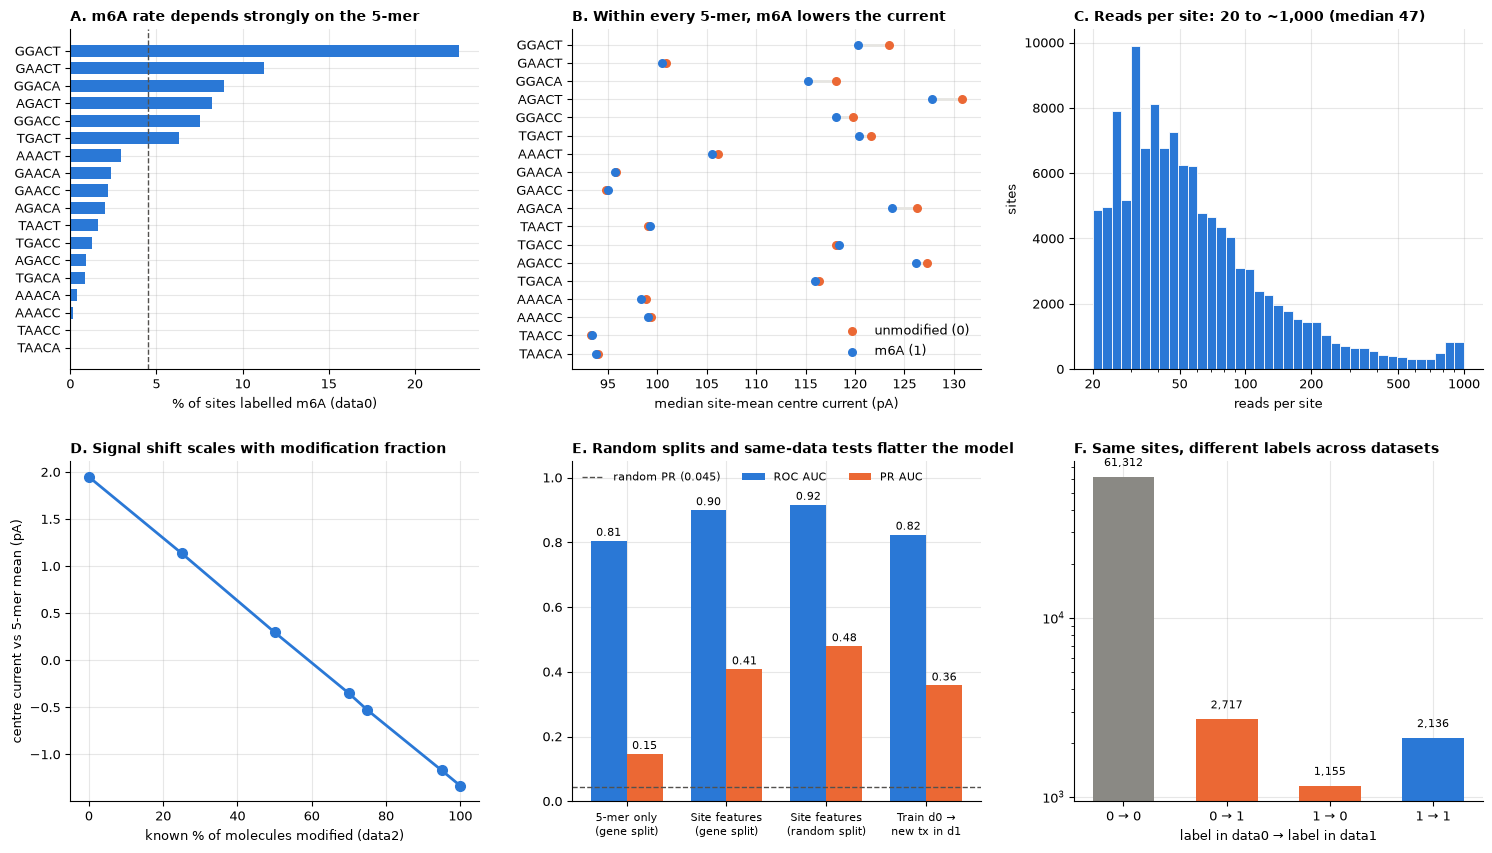

In [14]:
BLUE, ORANGE, GREY, LIGHT, INK = '#2a78d6', '#eb6834', '#8a8984', '#e6e5e1', '#52514e'
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 10, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})
fig, ax = plt.subplots(2, 3, figsize=(15, 8.6))

a = ax[0, 0]; kk = k.pos_rate.sort_values()
a.barh(kk.index, kk * 100, color=BLUE, height=.7); a.axvline(s0.label.mean() * 100, color=INK, ls='--', lw=1)
a.set_title('A. m6A rate depends strongly on the 5-mer'); a.set_xlabel('% of sites labelled m6A (data0)')

a = ax[0, 1]
for i, (n_, p_) in enumerate(zip(m[0], m[1])): a.plot([n_, p_], [i, i], color=LIGHT, lw=2, zorder=1)
a.scatter(m[0], range(len(m)), color=ORANGE, s=30, label='unmodified (0)', zorder=2)
a.scatter(m[1], range(len(m)), color=BLUE, s=30, label='m6A (1)', zorder=2)
a.set_yticks(range(len(m)), m.index); a.legend(frameon=False, loc='lower right')
a.set_title('B. Within every 5-mer, m6A lowers the current'); a.set_xlabel('median site-mean centre current (pA)')

a = ax[0, 2]; bins = np.logspace(np.log10(20), np.log10(1000), 40)
a.hist(s0.n_reads, bins=bins, color=BLUE, edgecolor='white', lw=.6); a.set_xscale('log')
a.set_xticks([20, 50, 100, 200, 500, 1000], ['20', '50', '100', '200', '500', '1000'])
a.set_title('C. Reads per site: 20 to ~1,000 (median 47)'); a.set_xlabel('reads per site'); a.set_ylabel('sites')

a = ax[1, 0]; a.plot(d2.index * 100, d2.mean_0_rel, color=BLUE, lw=2, marker='o', ms=7)
a.set_title('D. Signal shift scales with modification fraction')
a.set_xlabel('known % of molecules modified (data2)'); a.set_ylabel('centre current vs 5-mer mean (pA)')

a = ax[1, 1]
names = ['5-mer only\n(gene split)', 'Site features\n(gene split)', 'Site features\n(random split)', 'Train d0 →\nnew tx in d1']
order_e = ['5-mer only, split by gene', 'site features, split by gene', 'site features, RANDOM split', 'train d0 -> unseen transcripts in d1']
roc = [results[n][0] for n in order_e]; pr = [results[n][1] for n in order_e]   # computed in Section 11
x = np.arange(4); w = .36
for vals, col, lab, off in [(roc, BLUE, 'ROC AUC', -w/2), (pr, ORANGE, 'PR AUC', w/2)]:
    bars = a.bar(x + off, vals, w, color=col, label=lab)
    for b in bars: a.text(b.get_x() + b.get_width()/2, b.get_height() + .015, f'{b.get_height():.2f}', ha='center', fontsize=8)
a.axhline(.045, color=INK, ls='--', lw=1, label='random PR (0.045)')
a.set_xticks(x, names, fontsize=8); a.set_ylim(0, 1.05); a.legend(frameon=False, ncol=3, loc='upper left', fontsize=8)
a.set_title('E. Random splits and same-data tests flatter the model')

a = ax[1, 2]; ct = pd.crosstab(ov.label_d0, ov.label_d1)
vals = [ct.loc[0, 0], ct.loc[0, 1], ct.loc[1, 0], ct.loc[1, 1]]
a.bar(['0 → 0', '0 → 1', '1 → 0', '1 → 1'], vals, color=[GREY, ORANGE, ORANGE, BLUE], width=.6); a.set_yscale('log')
for i, v in enumerate(vals): a.text(i, v * 1.15, f'{v:,}', ha='center', fontsize=8)
a.set_title('F. Same sites, different labels across datasets'); a.set_xlabel('label in data0 → label in data1')

for a in ax.flat: a.grid(alpha=.3); a.set_axisbelow(True)
fig.tight_layout(h_pad=2.5, w_pad=2); fig.savefig('../docs/figures/EDA_pitfalls.png', dpi=160); plt.show()

### Pitfalls and what we will do about them

| # | Pitfall | Evidence | How we will handle it |
|---|---|---|---|
| 1 | Class imbalance | 4.5% positives (7.3% in data1) | ROC AUC + PR AUC, class weights / resampling, no accuracy |
| 2 | Variable read depth | 20–991 reads (median 47); data2 median 814 | Fixed-length summaries (median, quantiles) or read-level model with pooling; no count-dependent features |
| 3 | Gene-level clustering → leakage | 61% of positives in 10% of genes; neighbours of positives 10× more likely positive | Split and cross-validate grouped by `gene_id` |
| 4 | Sequence alone is predictive | GGACT 22.6% vs TAACA 0%; 5-mer-only ROC 0.81 | Report a sequence-only baseline; include k-mer as a feature |
| 5 | Simpson's paradox | Centre current effect +0.36 raw vs −0.69 within 5-mer | Normalise signal per 5-mer or always pair with k-mer |
| 6 | Heavy-tailed read features | Centre SD max 181 vs 99.9th pct 17 | Robust summaries, clipping / log transforms |
| 7 | Noisy, sample-specific labels | 3,872 label disagreements on 67k shared sites | Avoid over-tuning; remove overlapping transcripts/genes when validating on data1 |
| 8 | Batch effects between datasets | 0.2–0.4 pA current shift, higher SD in data1 | Per-dataset normalisation; cross-dataset validation |
| 9 | Partial modification weakens signal | Current shift linear in modified fraction (data2) | Read-distribution features or multiple-instance learning |
| 10 | Over-optimistic evaluation | PR 0.48 (random split) vs 0.41 (gene split) vs 0.36 (other dataset) | Gene-grouped CV + cross-dataset test; compare with baselines and m6Anet |